In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans,DBSCAN
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [ ]:
df=pd.read_csv("marketing_campaign.csv",sep='\t')

In [ ]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [ ]:
df.drop(['ID'],axis=1,inplace=True)

In [ ]:
df.drop(['Response'],axis=1,inplace=True)

In [ ]:
df.drop(['Z_CostContact','Z_Revenue'],axis=1,inplace=True)

In [ ]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce")
latest_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (latest_date - df["Dt_Customer"]).dt.days

In [ ]:
df


,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days
0,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,...,10,4,7,0,0,0,0,0,0,663
1,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,...,1,2,5,0,0,0,0,0,0,113
2,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,...,2,10,4,0,0,0,0,0,0,312
3,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,...,0,4,6,0,0,0,0,0,0,139
4,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,...,3,6,5,0,0,0,0,0,0,161
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,43,...,3,4,5,0,0,0,0,0,0,381
2236,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,0,...,2,5,7,0,0,0,1,0,0,19
2237,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,48,...,3,13,6,0,1,0,0,0,0,155
2238,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,30,...,5,10,3,0,0,0,0,0,0,156


In [ ]:
df.drop(['Dt_Customer'],axis=1,inplace=True)

In [ ]:
df['Age']=2022-df['Year_Birth']

In [ ]:
df.drop('Year_Birth',axis=1,inplace=True)

In [ ]:
df

,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days,Age
0,Graduation,Single,58138.0,0,0,58,635,88,546,172,...,4,7,0,0,0,0,0,0,663,65
1,Graduation,Single,46344.0,1,1,38,11,1,6,2,...,2,5,0,0,0,0,0,0,113,68
2,Graduation,Together,71613.0,0,0,26,426,49,127,111,...,10,4,0,0,0,0,0,0,312,57
3,Graduation,Together,26646.0,1,0,26,11,4,20,10,...,4,6,0,0,0,0,0,0,139,38
4,PhD,Married,58293.0,1,0,94,173,43,118,46,...,6,5,0,0,0,0,0,0,161,41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduation,Married,61223.0,0,1,46,709,43,182,42,...,4,5,0,0,0,0,0,0,381,55
2236,PhD,Together,64014.0,2,1,56,406,0,30,0,...,5,7,0,0,0,1,0,0,19,76
2237,Graduation,Divorced,56981.0,0,0,91,908,48,217,32,...,13,6,0,1,0,0,0,0,155,41
2238,Master,Together,69245.0,0,1,8,428,30,214,80,...,10,3,0,0,0,0,0,0,156,66


In [ ]:
marital_map={
    "Married":"Partnered",
    "Together":"Partnered",
    "Divorced":"Single",
    "Widow":"Single",
    "Alone":"Single",
    "Absurd":"Single",
    "YOLO":"Single",
    "Single":"Single",
}

In [ ]:
df['Marital_Status']=df['Marital_Status'].map(marital_map)

In [ ]:
df

,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days,Age
0,Graduation,Single,58138.0,0,0,58,635,88,546,172,...,4,7,0,0,0,0,0,0,663,65
1,Graduation,Single,46344.0,1,1,38,11,1,6,2,...,2,5,0,0,0,0,0,0,113,68
2,Graduation,Partnered,71613.0,0,0,26,426,49,127,111,...,10,4,0,0,0,0,0,0,312,57
3,Graduation,Partnered,26646.0,1,0,26,11,4,20,10,...,4,6,0,0,0,0,0,0,139,38
4,PhD,Partnered,58293.0,1,0,94,173,43,118,46,...,6,5,0,0,0,0,0,0,161,41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,Graduation,Partnered,61223.0,0,1,46,709,43,182,42,...,4,5,0,0,0,0,0,0,381,55
2236,PhD,Partnered,64014.0,2,1,56,406,0,30,0,...,5,7,0,0,0,1,0,0,19,76
2237,Graduation,Single,56981.0,0,0,91,908,48,217,32,...,13,6,0,1,0,0,0,0,155,41
2238,Master,Partnered,69245.0,0,1,8,428,30,214,80,...,10,3,0,0,0,0,0,0,156,66


In [ ]:
encoder=OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore")

In [ ]:
education_map = {
    'Basic': 'Undergraduate',
    '2n Cycle': 'Undergraduate',
    'Graduation': 'Graduate',
    'Master': 'Postgraduate',
    'PhD': 'Postgraduate'
}
df['Education'] = df['Education'].map(education_map)
cats = ['Education', 'Marital_Status']
encoded_features = encoder.fit_transform(df[cats])
encoded_df = pd.DataFrame(
    encoded_features,
    columns=encoder.get_feature_names_out(cats),
    index=df.index
)

df = pd.concat([df.drop(columns=cats), encoded_df], axis=1)



In [ ]:
df

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days,Age,Education_Postgraduate,Education_Undergraduate,Marital_Status_Single
0,58138.0,0,0,58,635,88,546,172,88,88,...,0,0,0,0,0,663,65,0.0,0.0,1.0
1,46344.0,1,1,38,11,1,6,2,1,6,...,0,0,0,0,0,113,68,0.0,0.0,1.0
2,71613.0,0,0,26,426,49,127,111,21,42,...,0,0,0,0,0,312,57,0.0,0.0,0.0
3,26646.0,1,0,26,11,4,20,10,3,5,...,0,0,0,0,0,139,38,0.0,0.0,0.0
4,58293.0,1,0,94,173,43,118,46,27,15,...,0,0,0,0,0,161,41,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,0,1,46,709,43,182,42,118,247,...,0,0,0,0,0,381,55,0.0,0.0,0.0
2236,64014.0,2,1,56,406,0,30,0,0,8,...,0,0,1,0,0,19,76,1.0,0.0,0.0
2237,56981.0,0,0,91,908,48,217,32,12,24,...,1,0,0,0,0,155,41,0.0,0.0,1.0
2238,69245.0,0,1,8,428,30,214,80,30,61,...,0,0,0,0,0,156,66,1.0,0.0,0.0


In [ ]:
print("Missing values before imputation:\n", df.isnull().sum()[df.isnull().sum() > 0])
if df['Income'].isnull().any():
    df['Income'] = df['Income'].fillna(df['Income'].median())
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_features, columns=df.columns)
display(df_scaled.head())

Missing values before imputation:
 Income    24
dtype: int64


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days,Age,Education_Postgraduate,Education_Undergraduate,Marital_Status_Single
0,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,0.843207,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,1.531185,0.985345,-0.786446,-0.360002,1.346874
1,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,-0.729006,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-1.190545,1.235733,-0.786446,-0.360002,1.346874
2,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,-0.038766,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-0.205773,0.317643,-0.786446,-0.360002,-0.742460
3,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,-0.748179,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-1.061881,-1.268149,-0.786446,-0.360002,-0.742460
4,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,-0.556446,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-0.953012,-1.017761,1.271543,-0.360002,-0.742460


In [ ]:
inertia=[]
k_range=range(2,8)
for k in k_range:
    kmeans=KMeans(n_clusters=k,random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)


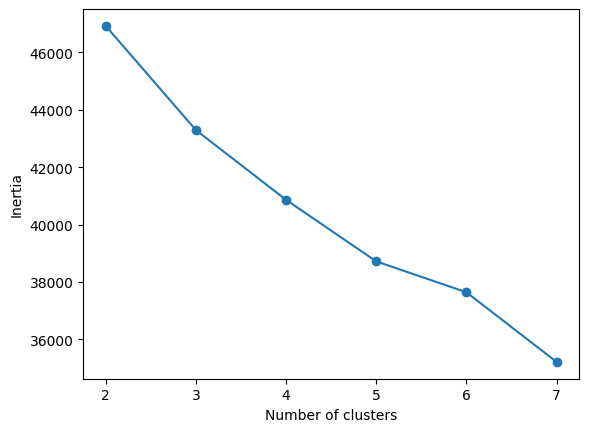

In [ ]:
plt.plot(k_range,inertia,marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

In [ ]:
kmeans_final=KMeans(n_clusters=4,random_state=42)

In [ ]:
cluster_labels=kmeans_final.fit_predict(df_scaled)

In [ ]:
cluster_labels
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(df_scaled)

df_pca = pd.DataFrame(
    pca_features,
    columns=['PCA1', 'PCA2'],
    index=df_scaled.index
)

df_pca['Cluster'] = cluster_labels

print(
    "2 components mein retained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

2 components mein retained variance: 33.21 %


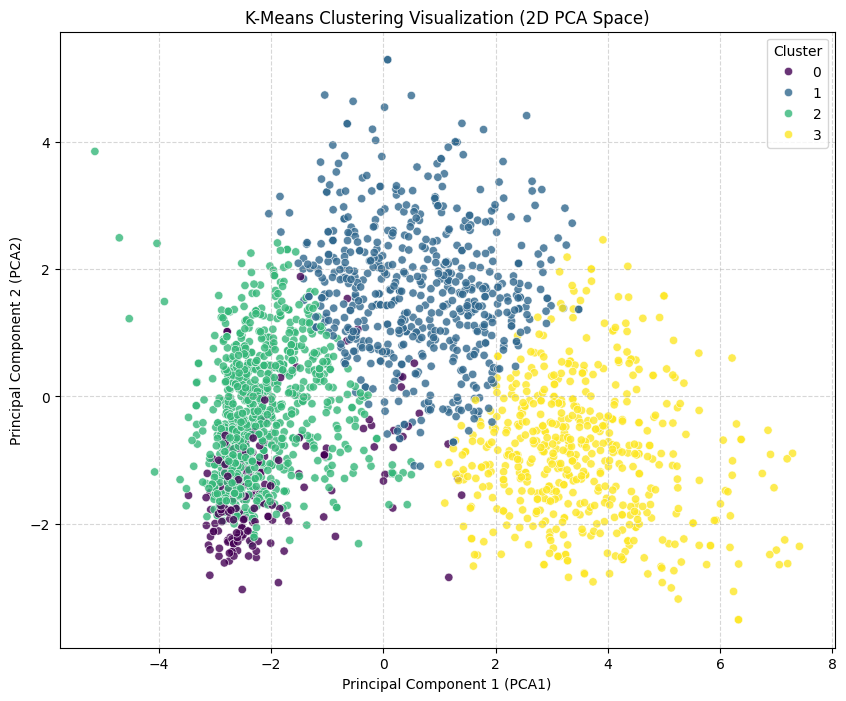

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='viridis',
    data=df_pca,
    alpha=0.8
)

plt.title('K-Means Clustering Visualization (2D PCA Space)')
plt.xlabel('Principal Component 1 (PCA1)')
plt.ylabel('Principal Component 2 (PCA2)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
dbscan=DBSCAN(eps=0.3,min_samples=5)
dbscan_label=dbscan.fit_predict(df_scaled)

In [ ]:
df_scaled['dbscan_label']=dbscan_label

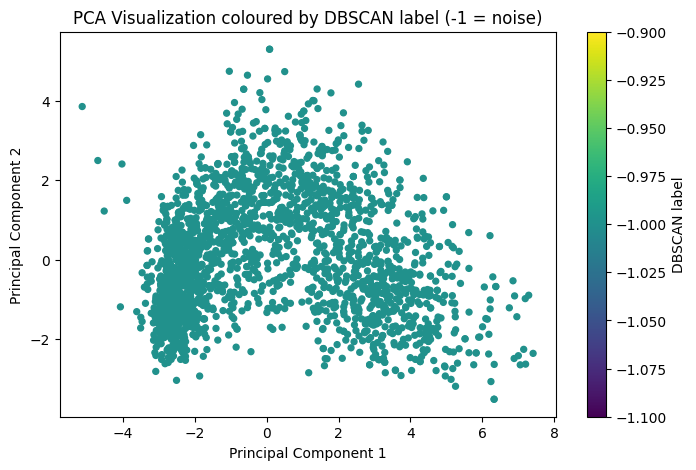

In [ ]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(pca_features[:, 0], pca_features[:, 1], c=dbscan_label, s=18)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization coloured by DBSCAN label (-1 = noise)")
plt.colorbar(scatter, label="DBSCAN label")
plt.show()

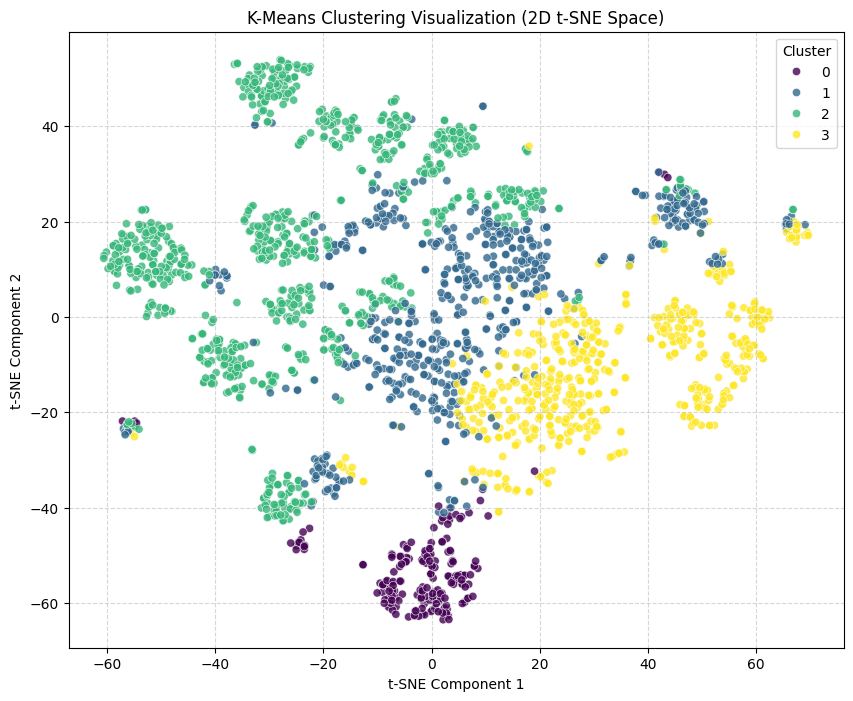

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
tsne_features = tsne.fit_transform(df_scaled)

df_tsne = pd.DataFrame(
    tsne_features,
    columns=['t-SNE1', 't-SNE2'],
    index=df_scaled.index
)
df_tsne['Cluster'] = cluster_labels
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='t-SNE1',
    y='t-SNE2',
    hue='Cluster',
    palette='viridis',
    data=df_tsne,
    alpha=0.8
)

plt.title('K-Means Clustering Visualization (2D t-SNE Space)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

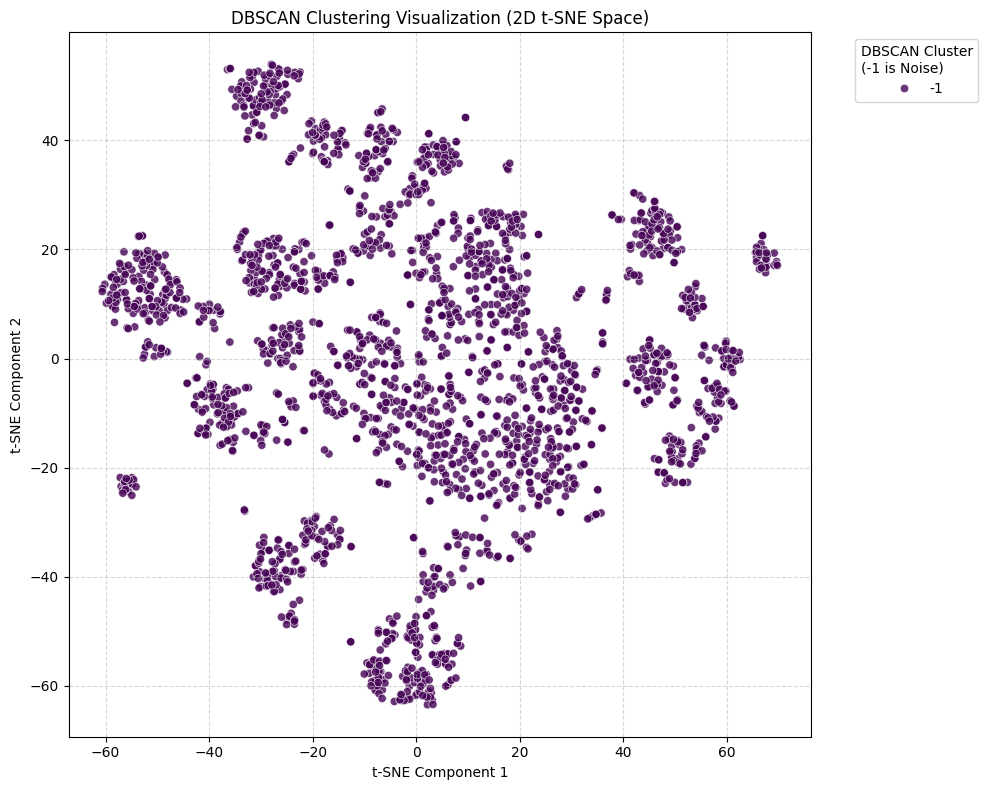

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
df_tsne_dbscan = df_tsne.copy()
df_tsne_dbscan['DBSCAN_Cluster'] = dbscan_label
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='t-SNE1',
    y='t-SNE2',
    hue='DBSCAN_Cluster',
    palette='viridis',
    data=df_tsne_dbscan,
    alpha=0.8
)

plt.title('DBSCAN Clustering Visualization (2D t-SNE Space)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(title='DBSCAN Cluster\n(-1 is Noise)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()